# Adam (Adaptive Moment Estimation) Optimizer

- It is the most popular optimizer for Neural Networks. It is the default optimizer in Keras and PyTorch.

# Problems with Previqous Optimizers

### Problem 1: Reaching Global Minimum slower

- SGD: It has a fixed learning rate, which is not good for Neural Networks. It can get stuck in local minima and saddle points. It is also sensitive to the choice of learning rate.

- Momentum: It reaches global minimum faster than SGD, but before reaching global minimum, it can overshoot and oscillate around the global minimum.

- NAG: It is a fix for Momentum's overshooting problem. It reaches global minimum faster than Momentum. But since it damps the oscillation, it might get stuck in a local minimum, where plain momentum would have enough inertia to escape.

### Problem 2: Loss function with elongated bowl problem

- AdaGrad: It fixes the problem of constant learning rate of SGD, Momentum and NAG. It gives a per-parameter learning rate: big gradients get a small rate, small gradients get a big rate. But it has a problem of shrinking learning rate. It can never reach the global minimum, because $v_t$ only ever grows, so $\eta_{\text{eff}}$ keeps shrinking. Late in training, updates can become too small and learning stalls.

- RMSProp: It fixes the problem of shrinking learning rate of AdaGrad. By introducing a decaying average of past squared gradients, it keeps the learning rate usable. It is one of the best optimizers for Neural Networks. 

<hr>

- Adam: It combines the benefits of both Momentum and RMSProp. It uses a decaying average of past gradients and squared gradients to adapt the learning rate for each parameter. It is the most popular optimizer for Neural Networks. 



# Mathematical Formulation of Adam

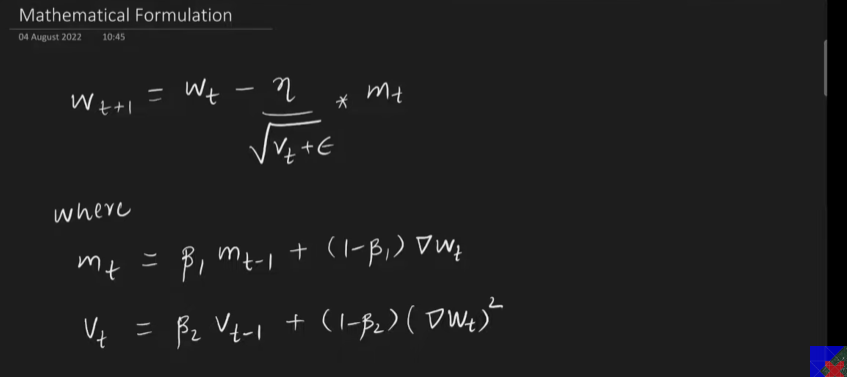

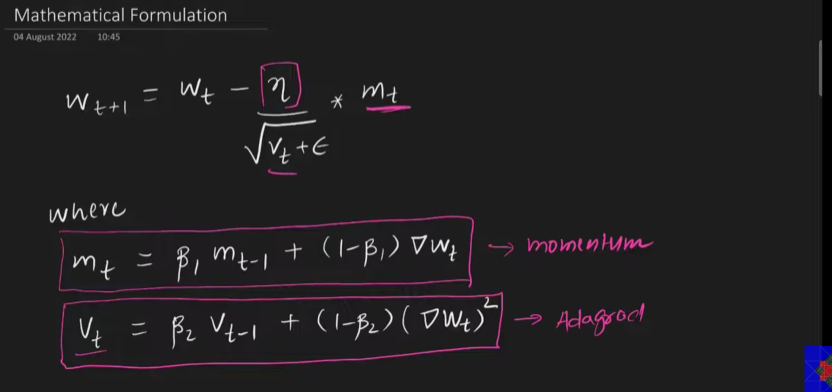

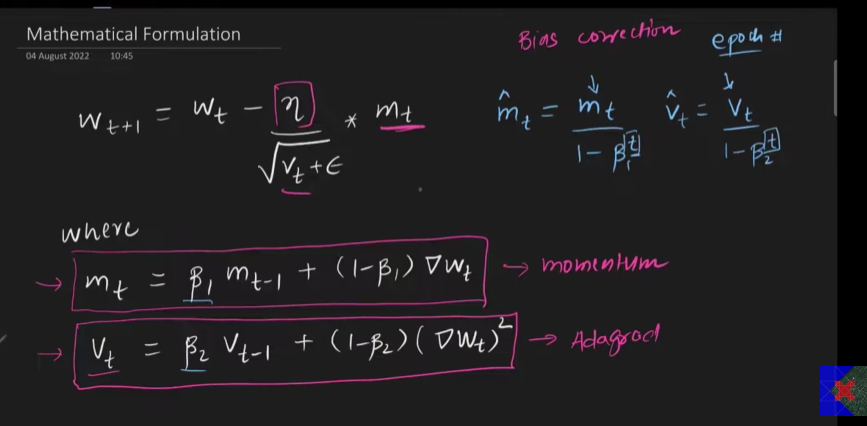

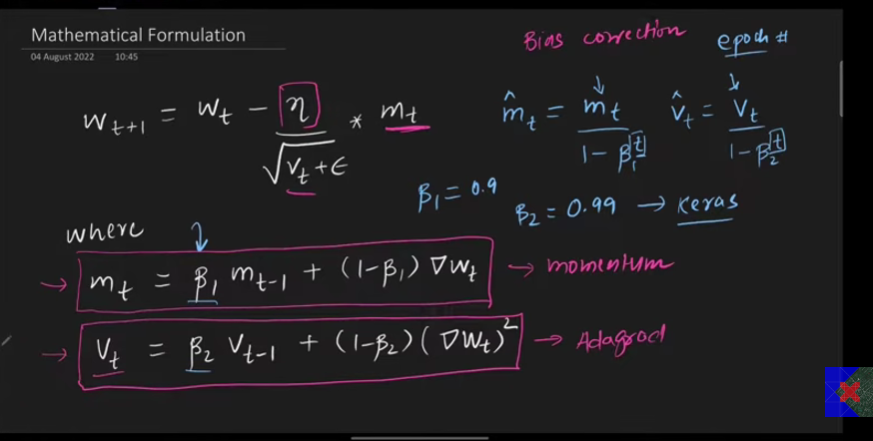

- After calculating $m_t$ and $v_t$, we need to do a bias correction, because both $m_t$ and $v_t$ are initialized to 0. So they are biased towards 0, especially during the initial time steps, and we need to correct that bias.

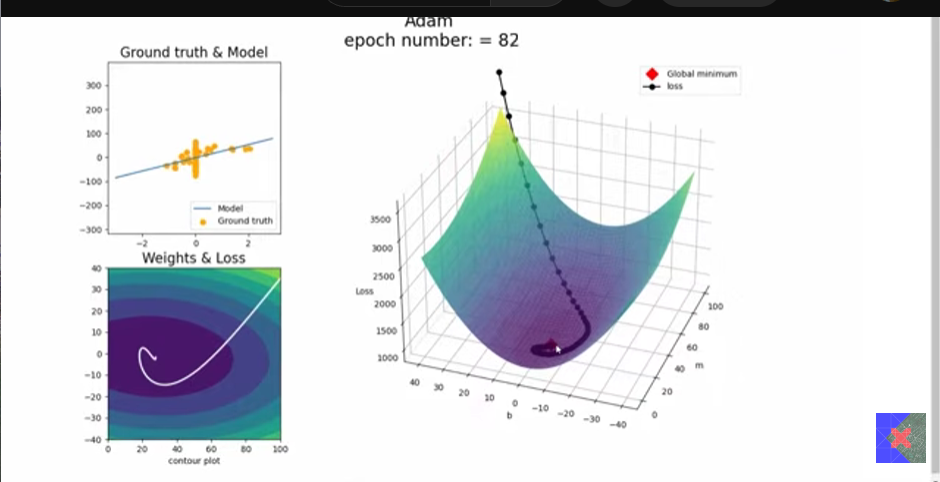

# Verdict

- Start with Adam optimizer. It is the most popular optimizer for Neural Networks. If you don't get good results with Adam, you can try RMSProp. It is still a very good optimizer for Neural Networks.

- Below you can see the claude generated notes:

<hr>

# Adam (Adaptive Moment Estimation)

## Idea
- Adam = Momentum + RMSProp + bias correction.
- Momentum part: follows the direction of recent gradients (smooth, faster).
- RMSProp part: gives each parameter its own learning rate (big gradients get a small rate, small gradients get a big rate).

## Symbols
- $\nabla w_t = \frac{\partial L}{\partial w}$ = gradient of the loss $L$ at step $t$
- $m_t$ = decaying average of gradients (momentum, the "direction")
- $v_t$ = decaying average of squared gradients (as in RMSProp, the "scale")
- $\beta_1 = 0.9$, $\beta_2 = 0.99$ (values on the slide)
- $\eta$ = base learning rate
- $\epsilon$ = tiny number so we never divide by zero
- $t$ = step number

## Formulas

1. Momentum term:

$$
m_t = \beta_1 \, m_{t-1} + (1 - \beta_1) \nabla w_t
$$

2. Squared-gradient term:

$$
v_t = \beta_2 \, v_{t-1} + (1 - \beta_2) (\nabla w_t)^2
$$

3. Bias correction:

$$
\hat{m}_t = \frac{m_t}{1 - \beta_1^{\,t}}, \qquad \hat{v}_t = \frac{v_t}{1 - \beta_2^{\,t}}
$$

4. Update:

$$
w_{t+1} = w_t - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \, \hat{m}_t
$$

- Same formulas for $b$.

## Why bias correction
- We start with $m_0 = 0$ and $v_0 = 0$.
- In the first few steps, $m_t$ and $v_t$ are pulled toward $0$, so they are too small.
- Dividing by $1 - \beta^t$ fixes this. At small $t$ the divisor is small, so the estimate is scaled up.
- As $t$ grows, $\beta^t \to 0$, the divisor becomes $1$, and the correction fades out.

## Quick summary
- $\hat{m}_t$ decides where to go (direction, smoothed).
- $\sqrt{\hat{v}_t}$ decides how big a step to take (per-parameter scaling).
- Adam combines both, which is why it is the common default optimizer.

## Note
- The slide uses $\beta_2 = 0.99$. The usual library default (Keras, PyTorch) is $\beta_2 = 0.999$.